In [72]:
pip install pandas numpy matplotlib seaborn scikit-learn umap-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import umap.umap_ as umap


In [89]:
df_ungrouped = pd.read_csv("NPFC-Test_Database_V2.csv")

# 1. Combine the 4 EEG channels into 1 average feature per frequency band
bands = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']
for band in bands:
    df_ungrouped[band] = df_ungrouped[[f'{band}_TP9', f'{band}_AF7', f'{band}_AF8', f'{band}_TP10']].mean(axis=1)

eeg_features = bands  # ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']

physiological_features = [
    'EDA',
    'BVP',
    'Temperature'
]

emotion_features = [
    'resmasknet_anger',
    #'resmasknet_disgust',
    #'resmasknet_fear',
    'resmasknet_happiness',
    'resmasknet_sadness',

]


self_reports = [
    'Selfreport_valence',
    'Selfreport_arousal',
    'Selfreport_focus'
]

# Combine input features
features = (
    eeg_features +
    physiological_features 
    + emotion_features #Sin emotional features obtenemos mejor varianza
)

# 2. Convert "HH:MM:SS" object column to total seconds and create 10-second bins
df_ungrouped['Task_Seconds'] = pd.to_timedelta(df_ungrouped['Task_Time']).dt.total_seconds()
df_ungrouped['Time_Bin_10s'] = (df_ungrouped['Task_Seconds'] // 10).astype(int)

# 3. Group by Subject_ID, Task_Num, Task_Type, and the 10-second interval
df = df_ungrouped.copy()
print(f"Number of rows pre group: {df.shape[0]}")

df = df.groupby(
    ['Subject_ID', 'Task_Num', 'Task_Type', 'Time_Bin_10s'], 
    as_index=False
).mean(numeric_only=True)

# 4. Select input data and labels
X = df[features].copy()
y_focus = df[['Selfreport_focus', 'Task_Num', 'Task_Type']].copy()
conditions = [
    y_focus['Selfreport_focus'] >= 3,
    y_focus['Selfreport_focus'] < 2
]
choices = [1, 0]
X = X.drop(columns=['Delta', 'Theta', 'Alpha', 'Gamma']) #'Beta'
y_focus['Selfreport_focus'] = np.select(conditions, choices, default=np.nan)
print("Number of features:", len(features))
print("Features:", features)
print(f"Number of rows: {df.shape[0]}")
print(f"Number of rows Focus: {y_focus.shape[0]}")

Number of rows pre group: 47905
Number of features: 11
Features: ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma', 'EDA', 'BVP', 'Temperature', 'resmasknet_anger', 'resmasknet_happiness', 'resmasknet_sadness']
Number of rows: 5361
Number of rows Focus: 5361


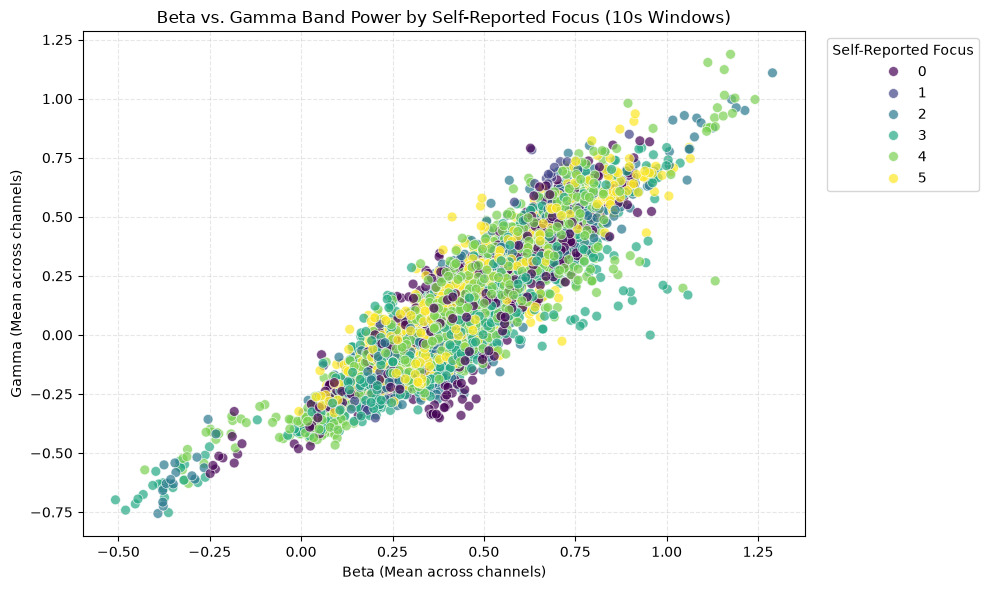

In [75]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Beta',
    y='Gamma',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7,
    s=50
)

plt.title('Beta vs. Gamma Band Power by Self-Reported Focus (10s Windows)')
plt.xlabel('Beta (Mean across channels)')
plt.ylabel('Gamma (Mean across channels)')
plt.legend(title='Self-Reported Focus', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [90]:
# PREPROCESSING

# Convert features to numeric, replacing invalid values with NaN
X = X.apply(pd.to_numeric, errors='coerce')

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely empty
X = X.dropna(axis=1, how='all')

# Update feature list
features = X.columns.tolist()

# Impute missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nPreprocessed shape:", X_scaled.shape)




Preprocessed shape: (5361, 7)


In [91]:

# =====================================================
# 4. PCA
# =====================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=df.index
)

pca_df[['Selfreport_focus', 'Task_Num','Task_Type']] = y_focus

print("\nPCA Explained Variance:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)
###
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=features
)

print(loadings.sort_values('PC1', key=abs, ascending=False))


PCA Explained Variance:
[0.20617466 0.16956096]
Total explained variance: 0.37573561930129906
                       PC1   PC2
resmasknet_anger      0.62 -0.20
resmasknet_sadness   -0.62 -0.25
Temperature           0.29 -0.45
EDA                   0.28 -0.24
Beta                  0.24  0.37
resmasknet_happiness  0.11  0.71
BVP                  -0.00  0.05


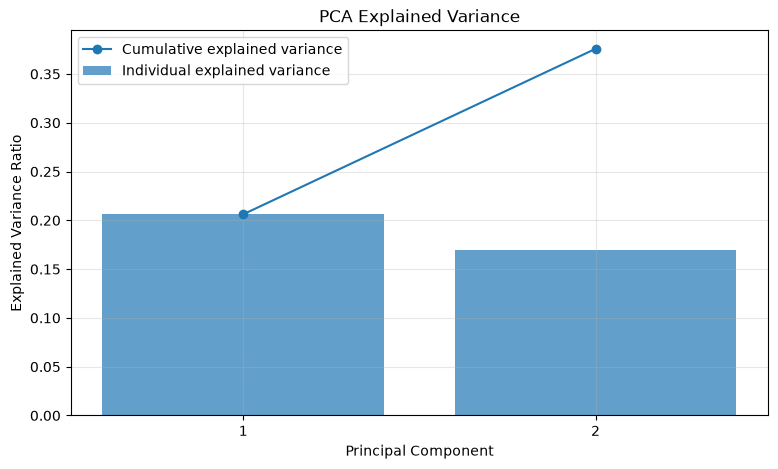

PC1: 0.20617466038284202
PC2: 0.16956095891845707
Total explained variance: 0.37573561930129906


In [92]:
# Varianza explicada individual
explained_variance = pca.explained_variance_ratio_

# Varianza acumulada
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label='Individual explained variance'
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    label='Cumulative explained variance'
)

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Explained Variance')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.show()
print("PC1:", pca.explained_variance_ratio_[0])
print("PC2:", pca.explained_variance_ratio_[1])

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

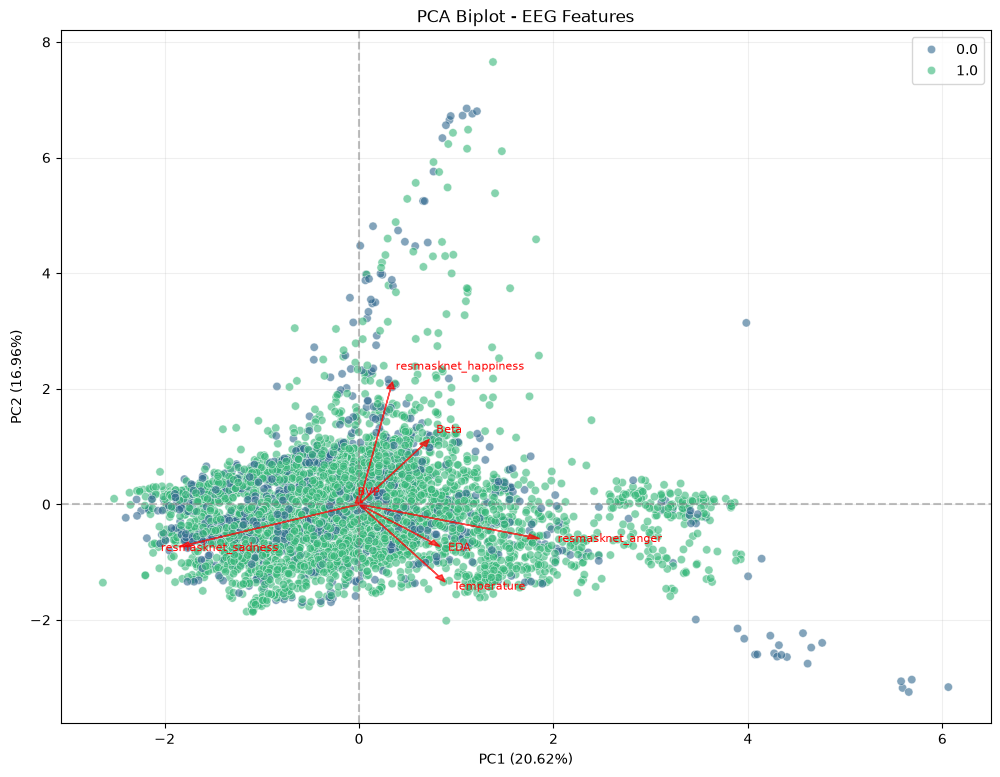

In [93]:
# =====================================================
# PCA BIPLOT
# =====================================================

plt.figure(figsize=(12, 9))

# Scatter de observaciones
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.6
)

# Escala para las flechas
scale = 3

# Vectores de las variables
for feature in features:

    x = loadings.loc[feature, 'PC1']
    y = loadings.loc[feature, 'PC2']

    plt.arrow(
        0, 0,
        x * scale,
        y * scale,
        color='red',
        alpha=0.7,
        head_width=0.08,
        length_includes_head=True
    )

    plt.text(
        x * scale * 1.1,
        y * scale * 1.1,
        feature,
        color='red',
        fontsize=8
    )

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")

plt.title('PCA Biplot - EEG Features')

plt.grid(alpha=0.2)
plt.legend()
plt.show()

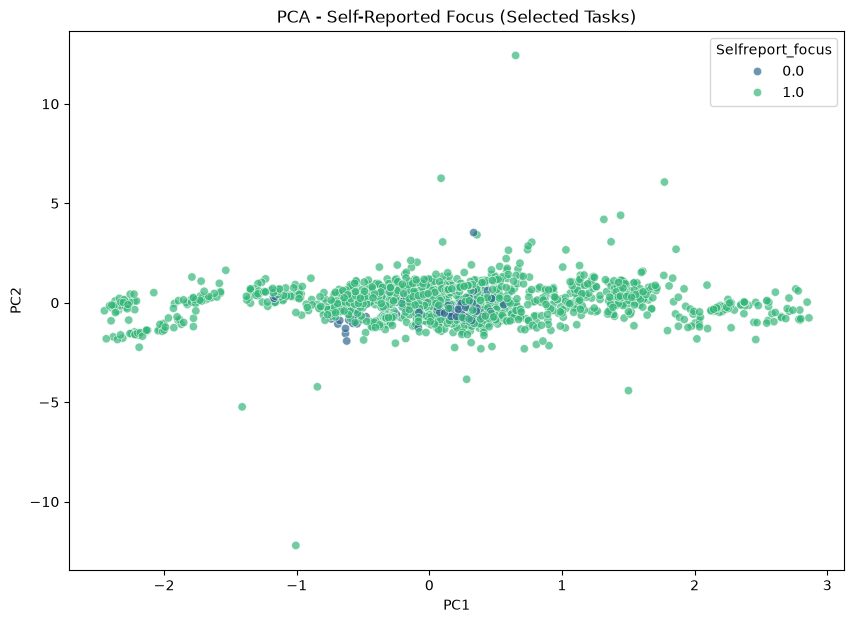

In [80]:
all_tasks = [
    [2.1, 8.1,], # meditations
    [3.1, 5.1, 5.2, 5.3, 5.4,], # mathematics
    [4.1, 6.1, 7.1, 7.2, 7.3, 7.4,], # Emotional
    [9.1, 1.1, 3.2, 5.5, 7.5, 6.2, 8.2, 4.2, 2.2] # Surveys
] 
selected_tasks = all_tasks[2]

pca_filtered = pca_df[pca_df['Task_Num'].isin(selected_tasks)]
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_filtered,
    x='PC1',
    y='PC2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('PCA - Self-Reported Focus (Selected Tasks)')
plt.show()


In [81]:
X_vif = df[features].copy()

print("NaN values:")
print(X_vif.isna().sum().sum())

print("\nInfinite values:")
print(np.isinf(X_vif.select_dtypes(include=np.number)).sum().sum())

print("\nConstant columns:")
print(X_vif.columns[X_vif.nunique() <= 1].tolist())

print("\nData types:")
print(X_vif.dtypes)

NaN values:
508

Infinite values:
0

Constant columns:
[]

Data types:
Beta           float64
EDA            float64
BVP            float64
Temperature    float64
dtype: object


In [82]:
nan_summary = pd.DataFrame({
    'NaN_Count': df[features].isna().sum(),
    'NaN_Percentage': df[features].isna().mean() * 100
})

nan_summary = nan_summary.sort_values(
    'NaN_Percentage',
    ascending=False
)

print(nan_summary)

             NaN_Count  NaN_Percentage
Beta               148            2.76
EDA                120            2.24
BVP                120            2.24
Temperature        120            2.24


In [71]:
import numpy as np
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = df[features].copy()

# Eliminar NaN
X_vif = X_vif.dropna()

# Agregar constante
X_vif = add_constant(X_vif)

# Calcular VIF
vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df = vif_df[vif_df['Feature'] != 'const']

vif_df = vif_df.sort_values(
    'VIF',
    ascending=False
)

pd.set_option('display.float_format', '{:.2f}'.format)
print(vif_df)

       Feature  VIF
2          EDA 1.01
4  Temperature 1.00
1         Beta 1.00
3          BVP 1.00


Conclusion, separamos focused y no focused a partir de 3 de self reported focus asignamos que esta concentrado, en las pruebas emocionales y de matematicas obtenemos que la mayoria se encuentra en estado de concentracion. Posible hipotesis: los valores de redmask generan muchos problemas con la varianza y no indican mucho, quiza podemos reducirlo a picos de emociones, ej 0.9 sería mucha certidumbre sobre esa emocion, por lo que es posible que la persona se ecuentre enfocada y por esto genera una respuesta emotiva